# Halcyon: Text-to-Image Generative Modeling without Language Pretraining

Halcyon is a decoder-only autoregressive model trained entirely from scratch, without a pretrained language model or text encoder.

This notebook demonstrates the tokenization and inference pipelines for Halcyon, including text-to-image generation and image captioning.

Specifically, we cover:

1. **Sequence format**: How text and image tokens are organized into a single sequence.
2. **Tokenization:** Encoding and decoding text and images using the Halcyon tokenizers.
3. **Text-to-image generation:** Sampling images with Halcyon-4B using classifier-free guidance.
4. **Image captioning:** Generating captions from images using the same model architecture.

The notebook runs on a single H100 GPU and prioritizes clarity over inference speed. For efficient batched inference across multiple GPUs, use `generate_images.py` and `caption_images.py`, which uses vLLM.

[Project page](https://keshik6.github.io/halcyon/) · [Models](https://huggingface.co/collections/radicalnumerics/halcyon) · [Blog](https://www.radicalnumerics.ai/blog/halcyon)

## 1. Setup

In [1]:
import sys, os, math
sys.path.insert(0, os.path.abspath(".."))  # repository root

import torch
from PIL import Image
from IPython.display import display
from huggingface_hub import hf_hub_download
from tokenizers import Tokenizer
from transformers import AutoModelForCausalLM, DynamicCache

import vocab
from image_tokenizer import ImageTokenizer

device = "cuda"
torch.backends.cuda.matmul.allow_tf32 = True
torch.set_grad_enabled(False)

MODEL = "radicalnumerics/Halcyon-4B"
TOKENIZERS = "radicalnumerics/Halcyon-Tokenizers"

/home/keshik/miniconda3/envs/halcyon/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. How Halcyon was trained

**Data.** Halcyon is trained on [GPIC](https://gpic.stanford.edu), 100M
permissively licensed image-text pairs, at 256x256, for one epoch (97,632 steps
at a global batch of 1,024).

**Tokenizers, both trained from scratch on GPIC.**
- *Text*: a byte-level BPE with 16,384 tokens.
- *Images*: a discrete cosmos-style image tokenizer (136M) with 8x spatial downsampling and
  a finite scalar quantization (FSQ) codebook of 8x8x8x5x5x5 = 64,000 codes. A
  256x256 image becomes a 32x32 grid, i.e. **1,024 image tokens**.

**One joint vocabulary** Text and image tokens share a single vocabulary of 80,640 ids:

| ids | description |
|---|---|
| 0 to 16,383 | text tokens |
| 16,384 to 80,383 | image tokens (16,384 + FSQ code) |
| 80,384 / 80,385 / 80,386 / 80,387 | `[SOV]` start of image / `[EOV]` end of image / `[PAD]` / `[EOS]` |

**Model.** A Qwen3-style decoder-only transformer, randomly initialized,
trained with next-token prediction over sequences of 1,280 tokens:

```
text-to-image rows:  caption  [SOV]  1024 image tokens  [EOV]  [EOS]
image-to-text rows:  [SOV]  1024 image tokens  [EOV]  caption  [EOS]
```

**Classifier-free guidance.** In 10% of text-to-image rows
the caption is dropped, leaving `[SOV] image [EOV] [EOS]`. The same model is then
both conditional (prompted with `caption [SOV]`) and unconditional (prompted
with `[SOV]`), and at sampling time the two predictions are combined.

**Two checkpoints for every model size** (Hugging Face branches):
- `baseline`: the paper's text-to-image model.
- `main`: trained with 10% image-to-text rows, so it can also caption images.

Let's look at the tokenizers first.

## 3. Tokenizers

### 3.1 Text tokenizer

In [2]:
text_tok = Tokenizer.from_file(hf_hub_download(TOKENIZERS, "tokenizer.json"))

caption = "A red fox sitting in fresh snow at dawn."
ids = text_tok.encode(caption).ids
print(len(ids), "tokens:", ids)
print([text_tok.decode([i]) for i in ids])

10 tokens: [32, 414, 10712, 1808, 280, 4552, 1198, 363, 14421, 13]
['A', ' red', ' fox', ' sitting', ' in', ' fresh', ' snow', ' at', ' dawn', '.']


### 3.2 Image tokenizer

`preprocess` takes the largest centered square crop of the image, resizes it to
256x256, and scales pixels to [-1, 1], exactly as in training. `encode` turns
the image into a 32x32 grid of image tokens, and `decode` turns tokens back into
an image.

codes: (1, 32, 32) range: 0 to 63944


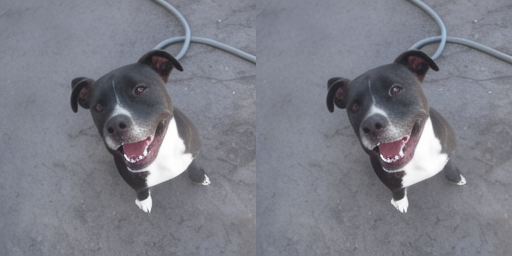

In [3]:
encoder = ImageTokenizer.from_pretrained(device=device, dtype=torch.bfloat16)
image_tok = ImageTokenizer.from_pretrained(device=device, dtype=torch.float32)

image = Image.open("../examples/sample.png").convert("RGB")
codes = encoder.encode(encoder.preprocess([image]))   # (1, 32, 32) FSQ codes
print("codes:", tuple(codes.shape), "range:", int(codes.min()), "to", int(codes.max()))

recon = image_tok.to_pil(image_tok.decode(codes))[0]
original = image_tok.to_pil(image_tok.preprocess([image]))[0]
side_by_side = Image.new("RGB", (512, 256))
side_by_side.paste(original, (0, 0))
side_by_side.paste(recon, (256, 0))
display(side_by_side)  # left: model input, right: reconstruction from 1,024 tokens

## 4. Text-to-image

We load **Halcyon-4B** from the `baseline` branch. Every Halcyon checkpoint is
a standard `Qwen3ForCausalLM`, so it loads with `transformers`.

In [4]:
t2i_model = AutoModelForCausalLM.from_pretrained(
    MODEL, revision="baseline", dtype=torch.bfloat16
).to(device).eval()
print(t2i_model.config)


Loading weights:   0%|                                                                                          | 0/398 [00:00<?, ?it/s]


Loading weights:  14%|███████████▎                                                                    | 56/398 [00:00<00:00, 557.67it/s]


Loading weights:  28%|██████████████████████▏                                                        | 112/398 [00:00<00:01, 274.90it/s]


Loading weights:  39%|██████████████████████████████▊                                                | 155/398 [00:00<00:00, 293.29it/s]


Loading weights:  47%|█████████████████████████████████████▌                                         | 189/398 [00:00<00:00, 299.00it/s]

...


Loading weights:  77%|█████████████████████████████████████████████████████████████▏                 | 308/398 [00:01<00:00, 254.30it/s]


Loading weights:  84%|██████████████████████████████████████████████████████████████████▎            | 334/398 [00:01<00:00, 251.53it/s]


Loading weights:  91%|███████████████████████████████████████████████████████████████████████▊       | 362/398 [00:01<00:00, 248.17it/s]


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 398/398 [00:01<00:00, 282.86it/s]

Qwen3Config {
  "architectures": [
    "Qwen3ForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": null,
  "dtype": "bfloat16",
  "eos_token_id": null,
  "head_dim": 128,
  "hidden_act": "silu",
  "hidden_size": 2560,
  "initializer_range": 0.02,
  "intermediate_size": 9728,
  "layer_types": [
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "ful

### 4.1 The sampling loop

Generating an image is 1,024 steps of next-token prediction. At each step we:

1. Run the model on the **conditional** sequence (`caption [SOV] ...`) and the
   **unconditional** sequence (`[SOV] ...`), each with its own KV cache.
2. Keep only the logits of image tokens (ids 16,384 to 80,383).
3. Combine them with classifier-free guidance:
   `logits = uncond + cfg_scale * (cond - uncond)`.
4. Sample one token and append it to **both** sequences.

After 1,024 steps the tokens, minus the 16,384 offset, are a 32x32 grid of FSQ
codes, which the image tokenizer decodes into a 256x256 image.

In [5]:
@torch.no_grad()
def generate_images(model, caption, num_images=4, cfg_scale=4.5, temperature=1.0, seed=1234):
    """Sample `num_images` images for one caption; returns (num_images, 1024) FSQ codes."""
    lo, hi = vocab.IMAGE_TOKEN_RANGE
    max_caption = vocab.max_caption_tokens(model.config.max_position_embeddings)
    caption_ids = text_tok.encode(caption.strip()).ids[:max_caption]

    cond = torch.tensor([caption_ids + [vocab.SOV_ID]] * num_images, device=device)
    uncond = torch.tensor([[vocab.SOV_ID]] * num_images, device=device)
    cond_cache, uncond_cache = DynamicCache(), DynamicCache()
    generator = torch.Generator(device).manual_seed(seed)

    tokens = []
    for _ in range(vocab.IMAGE_TOKENS):
        cond_logits = model(cond, past_key_values=cond_cache, use_cache=True).logits[:, -1, lo:hi]
        uncond_logits = model(uncond, past_key_values=uncond_cache, use_cache=True).logits[:, -1, lo:hi]
        logits = uncond_logits.float() + cfg_scale * (cond_logits.float() - uncond_logits.float())
        probs = torch.softmax(logits / temperature, dim=-1)
        next_code = torch.multinomial(probs, 1, generator=generator)  # index into the image span
        tokens.append(next_code)
        cond = uncond = next_code + lo  # feed the same image token to both branches

    return torch.cat(tokens, dim=1)  # FSQ codes, raster order


def show(images, cols=4):
    w, h = images[0].size
    rows = math.ceil(len(images) / cols)
    grid = Image.new("RGB", (cols * w, rows * h), "white")
    for i, im in enumerate(images):
        grid.paste(im, ((i % cols) * w, (i // cols) * h))
    display(grid)

### 4.2 Generate images

We now generate images from two text prompts using Halcyon-4B. This implementation is intended to illustrate the sampling procedure. For efficient batched generation, use `generate_images.py`.

A red fox sits in fresh snow at dawn, soft golden light on its fur and frosted pine trees behind it.


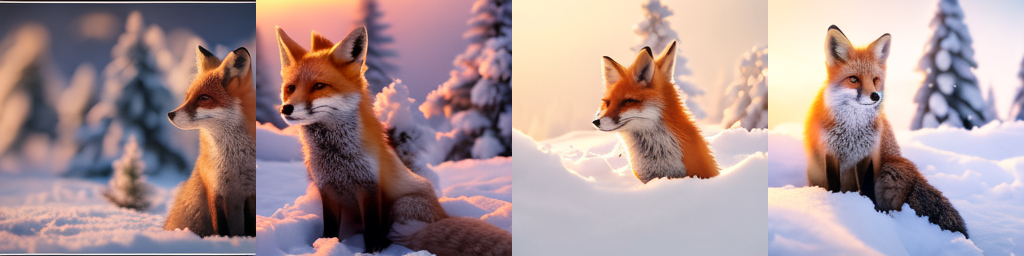

A slice of dark chocolate cake sits under a clear glass dome on a round wooden plate. The cake is covered in broken chocolate shavings and topped with small dollops of cream and two dark red cherries. The glass dome reflects light, creating bright streaks across the surface. The wooden plate rests on a light-colored countertop, and part of a metallic edge is visible at the bottom left. In the background, a blurred horizontal strip of what appears to be a counter or display case can be seen. A faint blue glow from an electronic screen or light source is reflected on the side of the cake. The overall scene is lit by warm, direct lighting that highlights the texture of the cake’s crumb and toppings.


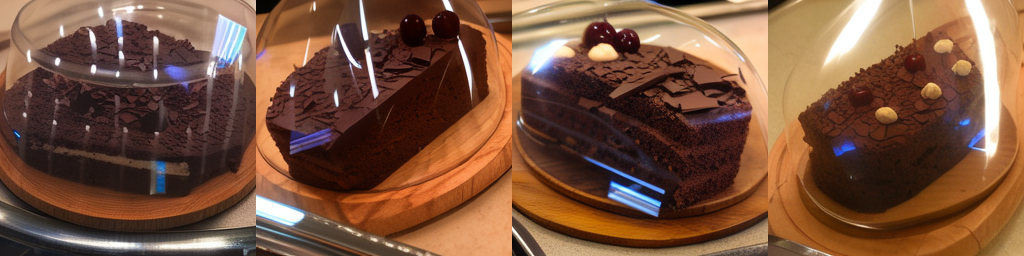

In [6]:
captions = [
    "A red fox sits in fresh snow at dawn, soft golden light on its fur and frosted pine trees behind it.",
    "A slice of dark chocolate cake sits under a clear glass dome on a round wooden plate. The cake is covered in broken chocolate shavings and topped with small dollops of cream and two dark red cherries. The glass dome reflects light, creating bright streaks across the surface. The wooden plate rests on a light-colored countertop, and part of a metallic edge is visible at the bottom left. In the background, a blurred horizontal strip of what appears to be a counter or display case can be seen. A faint blue glow from an electronic screen or light source is reflected on the side of the cake. The overall scene is lit by warm, direct lighting that highlights the texture of the cake’s crumb and toppings.",
]

generated = {}
for i, caption in enumerate(captions):
    codes = generate_images(t2i_model, caption, num_images=4, cfg_scale=5.2, seed=i) # Using a slightly higher cfg_scale for better fidelity.
    generated[caption] = image_tok.to_pil(image_tok.decode(codes))
    print(caption)
    show(generated[caption])

Experiment with different captions, random seeds, and guidance scales (`cfg_scale`). Increasing the guidance scale generally improves prompt adherence at the expense of diversity.

## 5. Image-to-text

Captioning needs the `main` branch, trained with image-to-text rows. We free the
text-to-image model first.

In [7]:
del t2i_model
torch.cuda.empty_cache()

i2t_model = AutoModelForCausalLM.from_pretrained(
    MODEL, revision="main", dtype=torch.bfloat16
).to(device).eval()


Loading weights:   0%|                                                                                          | 0/398 [00:00<?, ?it/s]


Loading weights:   6%|█████                                                                           | 25/398 [00:00<00:01, 223.15it/s]


Loading weights:  13%|██████████▋                                                                     | 53/398 [00:00<00:01, 212.10it/s]


Loading weights:  21%|████████████████▋                                                               | 83/398 [00:00<00:01, 237.77it/s]


Loading weights:  27%|█████████████████████▍                                                         | 108/398 [00:00<00:01, 228.60it/s]

...


Loading weights:  73%|█████████████████████████████████████████████████████████▎                     | 289/398 [00:01<00:00, 281.47it/s]


Loading weights:  80%|███████████████████████████████████████████████████████████████▎               | 319/398 [00:01<00:00, 278.66it/s]


Loading weights:  87%|████████████████████████████████████████████████████████████████████▉          | 347/398 [00:01<00:00, 269.75it/s]


Loading weights:  94%|██████████████████████████████████████████████████████████████████████████▍    | 375/398 [00:01<00:00, 265.50it/s]


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 398/398 [00:01<00:00, 263.51it/s]

### 5.1 The captioning loop

For image captioning, the input sequence consists of `[SOV]`, followed by 1,024 image tokens and `[EOV]`. The model then autoregressively predicts text tokens until it generates `[EOS]` or reaches the maximum token length.

We use greedy decoding by default. Setting a nonzero `temperature` enables sampling.

In [8]:
@torch.no_grad()
def caption_image(model, image, temperature=0.0, max_tokens=254, seed=1234):
    """Caption one PIL image."""
    codes = encoder.encode(encoder.preprocess([image])).reshape(1, -1)
    prompt = torch.cat(
        [
            torch.tensor([[vocab.SOV_ID]], device=device),
            codes.to(device) + vocab.IMG_OFFSET,
            torch.tensor([[vocab.EOV_ID]], device=device),
        ],
        dim=1,
    )
    cache = DynamicCache()
    generator = torch.Generator(device).manual_seed(seed)

    text_ids = []
    for _ in range(max_tokens):
        logits = model(prompt, past_key_values=cache, use_cache=True).logits[:, -1].float()
        if temperature > 0:
            next_id = torch.multinomial(torch.softmax(logits / temperature, -1), 1, generator=generator)
        else:
            next_id = logits.argmax(-1, keepdim=True)
        if next_id.item() == vocab.EOS_ID:
            break
        text_ids.append(next_id.item())
        prompt = next_id

    return text_tok.decode([t for t in text_ids if t < vocab.TEXT_VOCAB_SIZE])

### 5.2 Caption an input image

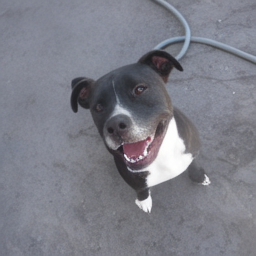

A black and white dog with brown eyes sits on a paved surface, looking up. A gray hose lies behind it.


In [9]:
image = Image.open("../examples/sample.png").convert("RGB")
display(image_tok.to_pil(image_tok.preprocess([image]))[0])  # what the model sees
print(caption_image(i2t_model, image))

We can also apply the image-to-text model to images generated in Section 4 and compare the predicted captions with the original prompts.

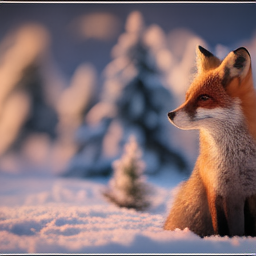

prompt:  A red fox sits in fresh snow at dawn, soft golden light on its fur and frosted pine trees behind it.


caption: A red fox sits in the snow, looking to the side. Snow-covered trees stand in the background.


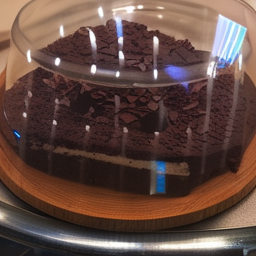

prompt:  A slice of dark chocolate cake sits under a clear glass dome on a round wooden plate. The cake is covered in broken chocolate shavings and topped with small dollops of cream and two dark red cherries. The glass dome reflects light, creating bright streaks across the surface. The wooden plate rests on a light-colored countertop, and part of a metallic edge is visible at the bottom left. In the background, a blurred horizontal strip of what appears to be a counter or display case can be seen. A faint blue glow from an electronic screen or light source is reflected on the side of the cake. The overall scene is lit by warm, direct lighting that highlights the texture of the cake’s crumb and toppings.


caption: A chocolate cake with white drizzle sits on a wooden plate inside a glass display case.


In [10]:
for caption, images in generated.items():
    display(images[0])
    print("prompt: ", caption)
    print("caption:", caption_image(i2t_model, images[0]))

## 6. Next steps

- **Batch inference.** `generate_images.py` and `caption_images.py` run the same
  models with vLLM across all available GPUs, from a single caption, a JSONL file of
  captions, a single image or a directory of images.
- **Other sizes.** Halcyon comes in 0.1B, 0.25B, 0.52B, 1.6B and 4B; change `MODEL`
  above. The paper's CFG scale per model is listed in the README.
- **Evaluation.** Score generated images with `gpic-eval` from
  [keshik6/gpic](https://github.com/keshik6/gpic).

The paper's models were trained and evaluated with a different internal stack.
This repository and the notebook are a faithful port of the inference pipeline,
and minor numerical differences are expected.